<a href="https://colab.research.google.com/github/Aigulya0/ml-practice/blob/main/Practice_04_Feature_Selection_B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Библиотеки успешно подключены!")


Библиотеки успешно подключены!


In [2]:

housing = fetch_california_housing(as_frame=True)

df = housing.frame.copy()

print("Датасет успешно загружен!")
print("Размер таблицы:", df.shape)

display(df.head())


Датасет успешно загружен!
Размер таблицы: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:

df.to_csv("california_housing.csv", index=False)

from google.colab import files
files.download("california_housing.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:

print("Размер датасета:")
print(df.shape)

print("\nТипы данных:")
print(df.dtypes)

print("\nПропущенные значения:")
print(df.isnull().sum())

print("\nОсновные статистики:")
display(df.describe())


Размер датасета:
(20640, 9)

Типы данных:
MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

Пропущенные значения:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Основные статистики:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [5]:

X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)


Обучающая выборка: (16512, 8)
Тестовая выборка: (4128, 8)


In [6]:

baseline_model = LinearRegression()

baseline_model.fit(X_train, y_train)

y_pred_base = baseline_model.predict(X_test)

mae_base = mean_absolute_error(y_test, y_pred_base)
rmse_base = np.sqrt(mean_squared_error(y_test, y_pred_base))
r2_base = r2_score(y_test, y_pred_base)

print("Базовая модель:")
print("MAE:", round(mae_base, 4))
print("RMSE:", round(rmse_base, 4))
print("R2:", round(r2_base, 4))


Базовая модель:
MAE: 0.5332
RMSE: 0.7456
R2: 0.5758


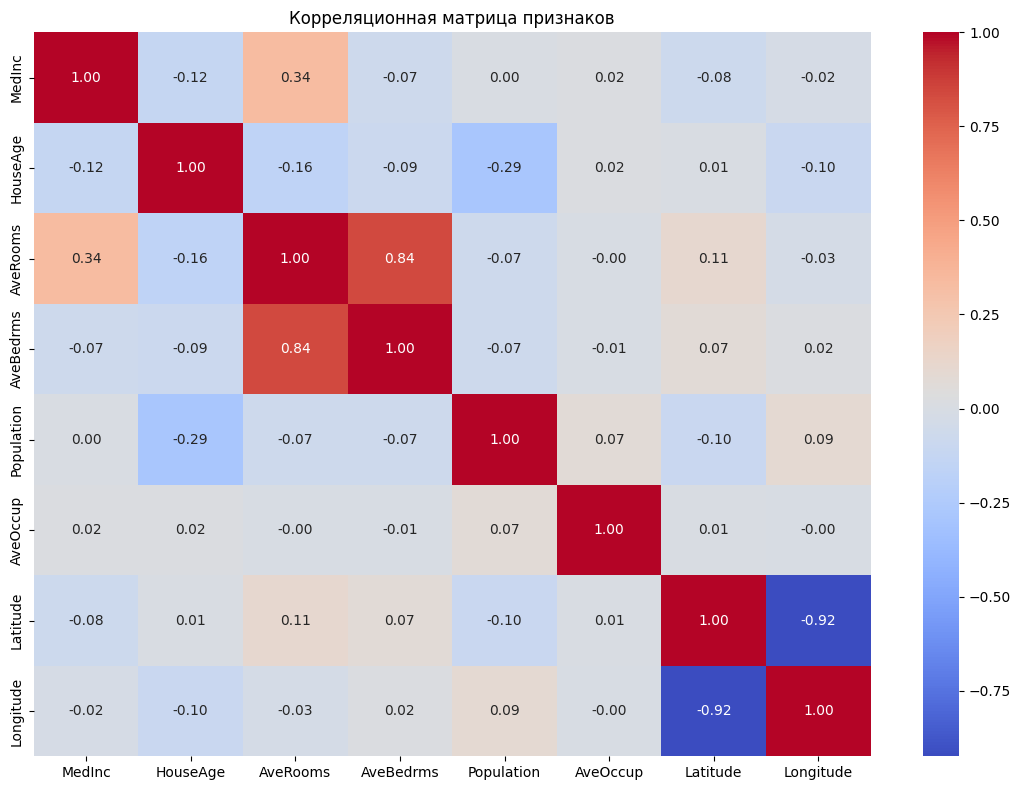

In [7]:

corr_matrix = X_train.corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Корреляционная матрица признаков")
plt.tight_layout()
plt.show()


In [8]:

threshold = 0.8

abs_corr = X_train.corr().abs()

upper = abs_corr.where(
    np.triu(np.ones(abs_corr.shape), k=1).astype(bool)
)

features_to_drop = [
    col for col in upper.columns
    if any(upper[col] > threshold)
]

selected_features = [
    col for col in X_train.columns
    if col not in features_to_drop
]

print("Удаляемые признаки:")
print(features_to_drop)

print("\nОставшиеся признаки:")
print(selected_features)

print("\nКоличество признаков до:", X_train.shape[1])
print("Количество признаков после:", len(selected_features))


Удаляемые признаки:
['AveBedrms', 'Longitude']

Оставшиеся признаки:
['MedInc', 'HouseAge', 'AveRooms', 'Population', 'AveOccup', 'Latitude']

Количество признаков до: 8
Количество признаков после: 6


In [9]:

X_train_reduced = X_train[selected_features]
X_test_reduced = X_test[selected_features]

reduced_model = LinearRegression()

reduced_model.fit(X_train_reduced, y_train)

y_pred_reduced = reduced_model.predict(X_test_reduced)

mae_reduced = mean_absolute_error(
    y_test, y_pred_reduced
)

rmse_reduced = np.sqrt(
    mean_squared_error(y_test, y_pred_reduced)
)

r2_reduced = r2_score(
    y_test, y_pred_reduced
)

print("Сокращённая модель:")
print("MAE:", round(mae_reduced, 4))
print("RMSE:", round(rmse_reduced, 4))
print("R2:", round(r2_reduced, 4))


Сокращённая модель:
MAE: 0.5983
RMSE: 0.8046
R2: 0.506


In [10]:

results = pd.DataFrame({
    "Модель": ["Базовая", "Сокращённая"],
    "Количество признаков": [
        X_train.shape[1],
        X_train_reduced.shape[1]
    ],
    "MAE": [mae_base, mae_reduced],
    "RMSE": [rmse_base, rmse_reduced],
    "R2": [r2_base, r2_reduced]
})

display(results.round(4))


,Модель,Количество признаков,MAE,RMSE,R2
0,Базовая,8,0.5332,0.7456,0.5758
1,Сокращённая,6,0.5983,0.8046,0.5060


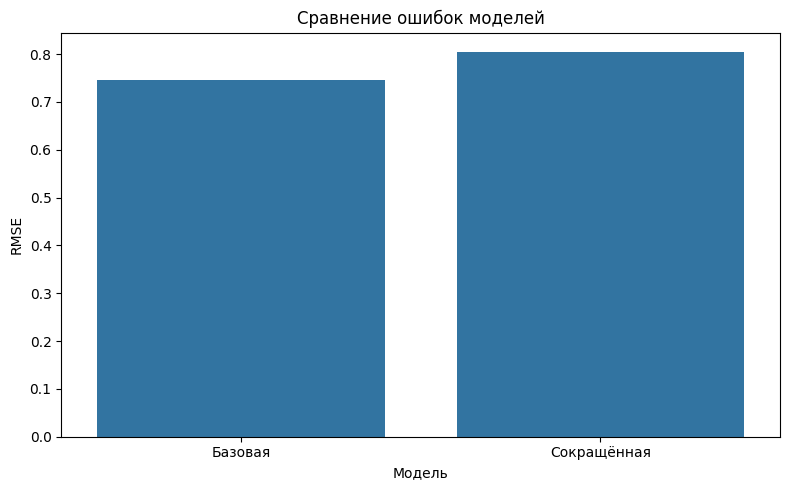

In [11]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=results,
    x="Модель",
    y="RMSE"
)

plt.title("Сравнение ошибок моделей")
plt.ylabel("RMSE")
plt.tight_layout()
plt.show()


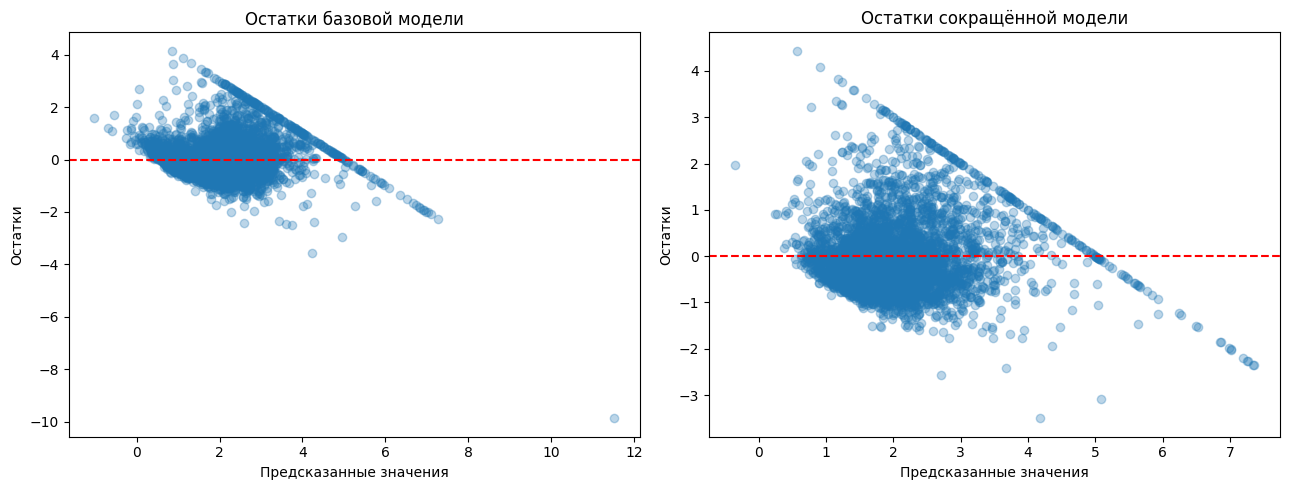

In [12]:

residuals_base = y_test - y_pred_base
residuals_reduced = y_test - y_pred_reduced

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(
    y_pred_base,
    residuals_base,
    alpha=0.3
)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Остатки базовой модели")
axes[0].set_xlabel("Предсказанные значения")
axes[0].set_ylabel("Остатки")

axes[1].scatter(
    y_pred_reduced,
    residuals_reduced,
    alpha=0.3
)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Остатки сокращённой модели")
axes[1].set_xlabel("Предсказанные значения")
axes[1].set_ylabel("Остатки")

plt.tight_layout()
plt.show()


In [13]:

if rmse_reduced < rmse_base:
    final_model_name = "Сокращённая"
    final_features = selected_features
    final_rmse = rmse_reduced
    final_r2 = r2_reduced
else:
    final_model_name = "Базовая"
    final_features = list(X_train.columns)
    final_rmse = rmse_base
    final_r2 = r2_base

print("Выбранная модель:", final_model_name)
print("Признаки:", final_features)
print("RMSE:", round(final_rmse, 4))
print("R2:", round(final_r2, 4))


Выбранная модель: Базовая
Признаки: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
RMSE: 0.7456
R2: 0.5758


Вывод по практической работе №4

В работе использовался датасет California Housing. Была обучена базовая линейная регрессия на восьми числовых признаках.

Для проверки мультиколлинеарности построена корреляционная матрица. Признаки с абсолютной корреляцией выше 0.8 были исключены при создании сокращённой модели.

Обе модели оценивались на одинаковой тестовой выборке с помощью MAE, RMSE и R².

Финальная модель: [вписать результат шага 13].
RMSE: [вписать значение].
R²: [вписать значение].

По графикам остатков: [описать обнаруженные закономерности].

Выбранный набор признаков обоснован сравнением качества прогнозов. Сокращение числа признаков само по себе не гарантирует улучшения модели.

# Практическая работа №4 — Сравнение наборов признаков

## Общая информация

**Вариант:** B  
**Тема:** Сравнение наборов признаков и выбор финальной модели линейной регрессии  
**Среда разработки:** Google Colab  
**Язык программирования:** Python

## Цель работы

Обучить базовую модель линейной регрессии, исследовать мультиколлинеарность признаков, построить сокращённую модель и сравнить качество прогнозирования.

## Используемый датасет

**Название:** California Housing Dataset

Датасет содержит 20 640 наблюдений о характеристиках районов Калифорнии.

- Количество исходных признаков: 8
- Целевая переменная: `MedHouseVal`
- Тип задачи: регрессия
- Источник: [California Housing](https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html)

## Используемые библиотеки

- pandas — обработка данных
- numpy — числовые вычисления
- matplotlib — визуализация
- seaborn — корреляционная матрица
- scikit-learn — обучение и оценка моделей

## Этапы выполнения

1. Загрузка датасета California Housing.
2. Первичный анализ структуры данных.
3. Разделение данных на обучающую и тестовую выборки.
4. Обучение базовой модели линейной регрессии.
5. Построение корреляционной матрицы.
6. Выявление и удаление избыточных признаков.
7. Обучение сокращённой модели.
8. Сравнение моделей по MAE, RMSE и R².
9. Анализ графиков остатков.
10. Выбор финальной модели.

## Метод отбора признаков

Для обнаружения мультиколлинеарности использована корреляционная матрица.

Порог абсолютной корреляции установлен на уровне 0.8.

Если два признака имеют корреляцию выше этого порога, один из них исключается из сокращённой модели.

## Результаты

| Метрика | Базовая модель | Сокращённая модель |
|---|---|---|
| Количество признаков | 8 | Заполнить |
| MAE | Заполнить | Заполнить |
| RMSE | Заполнить | Заполнить |
| R² | Заполнить | Заполнить |

Значения необходимо перенести из результатов выполнения Google Colab.

## Анализ остатков

Построены графики остатков базовой и сокращённой моделей.

По ним оцениваются возможные систематические закономерности, нелинейность и неодинаковый разброс ошибок.

**Наблюдения:** заполнить после анализа графиков.

## Вывод

В ходе практической работы выполнено сравнение двух моделей линейной регрессии.

Базовая модель обучена на всех числовых признаках. Для сокращённой модели проведён анализ корреляций и исключены признаки с высокой взаимной зависимостью.

Качество моделей оценено с помощью MAE, RMSE и R².

**Выбранная модель:** заполнить по результатам.

**Обоснование выбора:** указать, какая модель имеет меньший RMSE и как изменилось количество признаков.

## Структура репозитория

```text
ml-practice-04-feature-selection/
│
├── data/
│   └── california_housing.csv
│
├── notebooks/
│   └── Practice_04_Feature_Selection_B.ipynb
│
└── README.md
```

## Запуск проекта

1. Открыть Google Colab.
2. Загрузить ноутбук из папки `notebooks`.
3. Подключиться к среде выполнения.
4. Выполнить ячейки по порядку.
5. Изучить результаты сравнения моделей.

Датасет также можно автоматически загрузить с помощью `fetch_california_housing` из библиотеки scikit-learn.